# Zwei Tarifmerkmale und die Erklärung des Schadenbedarfs

Wie viel gemeinsame Vorhersageinformation bleibt mit Fahreralter und genau einem weiteren Risikomerkmal? Was zeigen Geografie, Alter und Vertragsdauer, und welche Mechanismen bleiben offen?

Dieses Notebook zeigt die ausgeführten Entwicklungs-OOF-Ergebnisse des begrenzten Vergleichs. Die S5-Evaluation ist bereits geöffnet und wird für diese neue Auswahl nicht verwendet. [Aktuarische Einordnung und mündliche Antworten](../docs/aktuarische_einordnung.md) erläutern die Befunde, Kosten und Transfergrenzen.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd() if (Path.cwd() / 'reports').is_dir() else Path.cwd().parent
import sys
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.data import sha256, text_sha256

REPORTS = ROOT / 'reports/s6a'
report = json.loads((REPORTS / 'report.json').read_text(encoding='utf-8'))
for relative, expected in report['identity']['source_sha256'].items():
    assert text_sha256(ROOT / relative) == expected, relative
assert text_sha256(ROOT / 'config/interpretation_protocol.json') == report['identity']['config_sha256']
evidence = json.loads((REPORTS / 'evidence.json').read_text(encoding='utf-8'))
for relative, expected in evidence['files_sha256'].items():
    assert sha256(ROOT / relative) == expected, relative
def table(name):
    return pd.read_json(REPORTS / f'{name}.json')
display(pd.DataFrame([{'Lauf': report['run_id'], 'Quelle': report['identity']['source_id'],
                      'Split': report['identity']['split_id'], **report['population']}]))

,Lauf,Quelle,Split,claims,exposure_years,loss_eur,policies
0,s6af8e1bc99500e7ac6,cas-744e13a80283a07a,s2split-fe11d414168572dd,21066,286880.818827,47480754.65,542392


## Vier Paare, zwei transparente Spezifikationen

Alle Regeln erhalten genau `DrivAge` und `Area`, `Density`, `Region` oder `BonusMalus`. Das reduzierte GAM verwendet einen additiven kubischen Splineansatz mit Ridge-Strafe; seine Strafe ist nicht die Differenzenstrafe des vollständigen S4-GAM. Die Schadenhöhe ist je Fold ein einziges Trainingsclaim-Mittel, einschließlich der Vorhersage für Nullschadenverträge. Exponierung ist Gewicht und Periodenskalierung.

Hauptkriterium: exponierungsgewichtete **Jahresraten**-Tweedie-Deviance mit festem p=1,5. `pp_hgb_mean` ist die unveränderte vollständige S5-OOF-Referenz. A/P bezeichnet beobachteten durch erwarteten Verlust.

,model_id,tweedie_deviance_per_exposure,frequency_deviance_per_exposure,predicted_annual_loss_cost,actual_over_predicted
0,pp_hgb_mean,79.194844,NaN,165.555589,0.999706
3,two_BonusMalus_gam,82.027856,0.460067,165.482662,1.000146
4,two_BonusMalus_glm,82.620512,0.460982,165.478771,1.000170
5,two_Density_gam,84.057302,0.471659,165.501173,1.000035
1,two_Area_gam,84.181046,0.471830,165.500004,1.000042
7,two_Region_gam,84.216007,0.472787,165.502442,1.000027
6,two_Density_glm,84.503809,0.472206,165.505097,1.000011
2,two_Area_glm,84.620291,0.472315,165.503346,1.000021
8,two_Region_glm,84.667702,0.473324,165.504859,1.000012


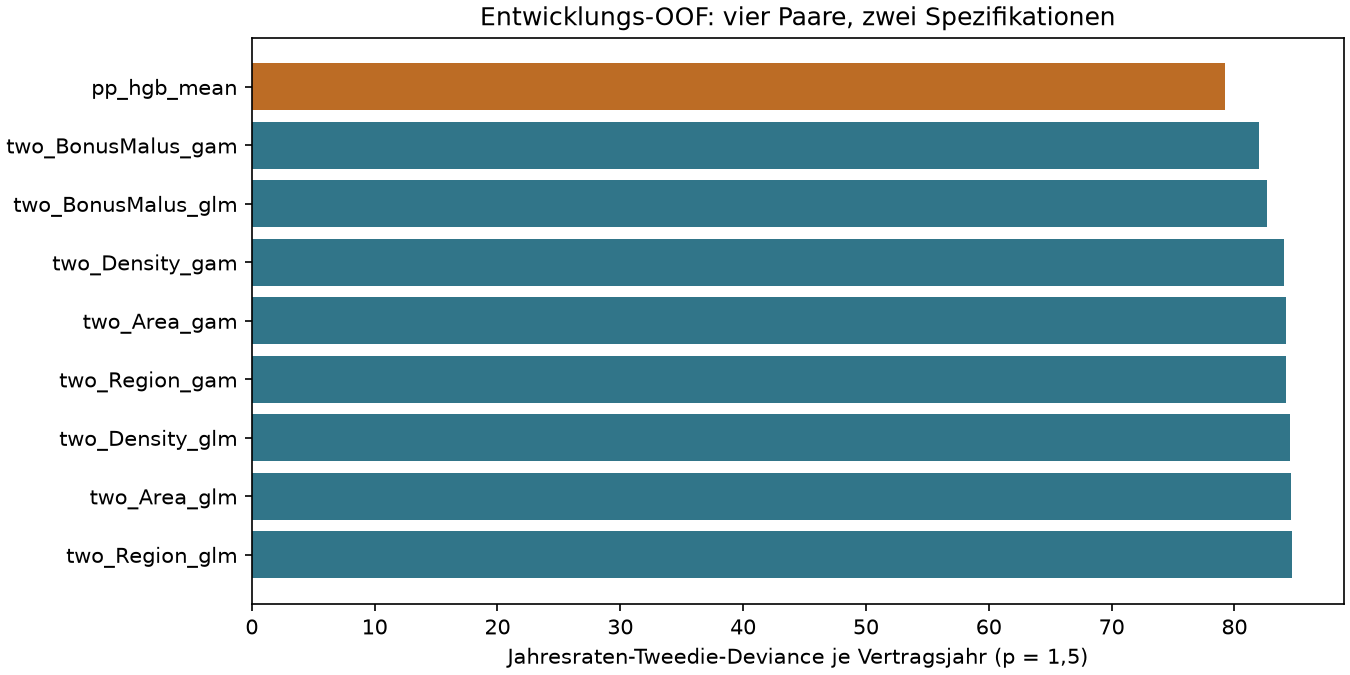

**Empfehlung im registrierten Kreis:** `two_BonusMalus_gam`. Gegenüber dem vollständigen OOF-Modell steigt die Jahresratendeviance um 3.58 %. Das ist explorative Entwicklungsinformation, keine neue unabhängige Testbestätigung.

In [2]:
scores = table('scores').sort_values('tweedie_deviance_per_exposure')
display(scores[['model_id', 'tweedie_deviance_per_exposure', 'frequency_deviance_per_exposure',
                'predicted_annual_loss_cost', 'actual_over_predicted']].round(6))
display(Image(filename=str(REPORTS / 'figures/zwei_merkmale.png')))
best = report['best_registered_candidate']
reference = scores.set_index('model_id').loc['pp_hgb_mean', 'tweedie_deviance_per_exposure']
score = scores.set_index('model_id').loc[best, 'tweedie_deviance_per_exposure']
display(Markdown(f'**Empfehlung im registrierten Kreis:** `{best}`. Gegenüber dem vollständigen OOF-Modell steigt die Jahresratendeviance um {(score/reference-1)*100:.2f} %. Das ist explorative Entwicklungsinformation, keine neue unabhängige Testbestätigung.'))

In [3]:
display(table('bootstrap_full')[['model_id', 'deviance_difference', 'lower', 'upper']].round(6))
display(table('bootstrap_best')[['model_id', 'deviance_difference', 'lower', 'upper']].round(6))
display(table('fold_scores').pivot(index='fold', columns='model_id', values='tweedie_deviance_per_exposure').round(4))
display(table('severity_scores')[['model_id', 'claims', 'observed_claim_mean_eur', 'predicted_claim_mean_eur', 'mean_gamma_deviance']].round(4))

,model_id,deviance_difference,lower,upper
0,pp_hgb_mean,0.000000,0.000000,0.000000
1,two_Area_gam,4.986202,3.063302,7.922138
2,two_Area_glm,5.425447,3.200965,9.118707
3,two_BonusMalus_gam,2.833012,1.462608,4.807079
4,two_BonusMalus_glm,3.425669,1.477055,6.680846
5,two_Density_gam,4.862458,3.034252,7.639330
6,two_Density_glm,5.308966,3.182444,8.842824
7,two_Region_gam,5.021164,3.158190,7.667503
8,two_Region_glm,5.472859,3.262770,8.953105


,model_id,deviance_difference,lower,upper
0,pp_hgb_mean,-2.833012,-4.807079,-1.462608
1,two_Area_gam,2.153190,1.438792,3.122576
2,two_Area_glm,2.592435,1.531030,4.258368
3,two_BonusMalus_gam,0.000000,0.000000,0.000000
4,two_BonusMalus_glm,0.592656,-0.188276,1.959059
5,two_Density_gam,2.029446,1.356822,2.830714
6,two_Density_glm,2.475953,1.495097,3.994952
7,two_Region_gam,2.188151,1.548449,2.964613
8,two_Region_glm,2.639846,1.662682,4.103594


model_id,pp_hgb_mean,two_Area_gam,two_Area_glm,two_BonusMalus_gam,two_BonusMalus_glm,two_Density_gam,two_Density_glm,two_Region_gam,two_Region_glm
fold,,,,,,,,,
1,80.6488,84.6648,84.9419,82.7183,83.2184,84.5642,84.8924,84.5679,84.9089
2,78.8088,81.1582,81.1664,79.8134,79.4726,81.1547,81.1788,81.0778,81.0662
3,74.5422,80.7452,80.7287,78.6915,78.2884,80.5512,80.5405,81.0489,81.0450
4,73.9025,76.5223,76.6467,74.8991,74.6380,76.5555,76.6999,76.4702,76.5828
5,88.0797,97.7991,99.6013,94.0061,97.4722,97.4466,99.1924,97.8977,99.7171


,model_id,claims,observed_claim_mean_eur,predicted_claim_mean_eur,mean_gamma_deviance
0,severity_mean,21066,2253.9046,2254.9154,1.7735


Die Intervalle stammen aus 500 gepaarten Ziehungen ganzer Verträge, einschließlich aller Nullschäden und Claimzeilen. Der Exponierungsnenner wird mitgezogen. Die Intervalle gelten bedingt auf feste Fits, umfassen keine erneute Modellanpassung oder Paarwahl und können Portfoliokalibrierung nicht in Segmentkalibrierung verwandeln. Das Intervall BM-GLM minus BM-GAM enthält null: Der bessere GAM-Punktwert trennt diese beiden Spezifikationen unter der bedingten Unsicherheitsbetrachtung nicht eindeutig. Die Empfehlung für das Paar ist stärker als eine eindeutige Rangbehauptung zwischen seinen GLM-/GAM-Regeln.

## Wohngebiet, Schadenhöhe und Tail

AB, CD, EF fassen vorab Area-Stufen zusammen. Area/Density beschreiben den Wohnort; Region ist eine historische Vertragsregion. Beobachtete Zahlbeträge sind keine direkte Messung physischer Unfallenergie. Häufigkeit und Schadenbedarf beziehen Nullschadenverträge ein; Median und Quantile betreffen positive Schadenzeilen.

,geo,policies,exposure_years,claims,frequency,severity_eur,severity_median_eur,severity_p99_eur,annual_loss_eur,loss_share_ge_100000,annual_loss_capped_100000
0,AB,143587,83974.0226,4806,0.0572,2878.6029,1172,17014.8090,164.7482,0.4315,105.5714
1,CD,274750,145362.1719,10805,0.0743,2078.7341,1172,15203.7788,154.5156,0.1824,136.6546
2,EF,124055,57544.6244,5455,0.0948,2050.4980,1172,16558.0648,194.3790,0.1599,173.7230


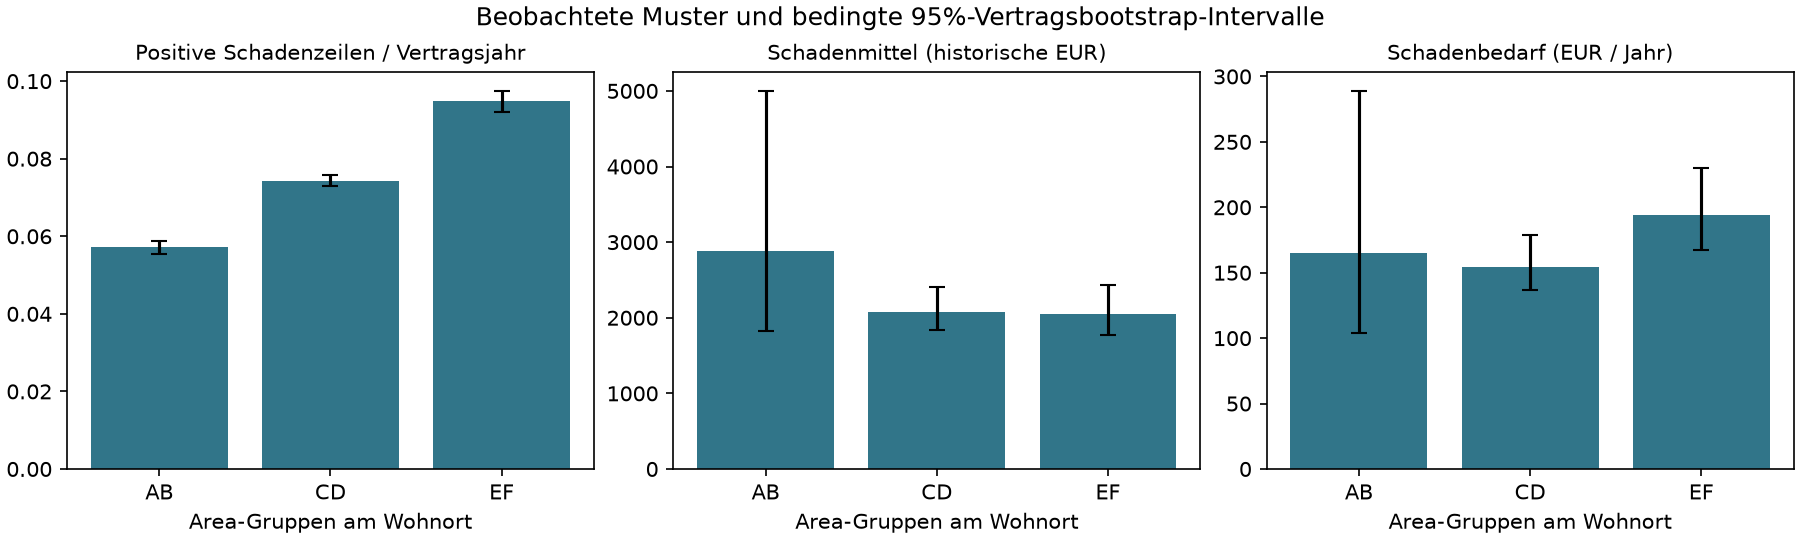

,age,policies,exposure_years,claims,frequency,severity_eur,annual_loss_eur
0,0,24175,9983.8922,1575,0.1578,5640.6549,889.8365
1,1,112770,51739.7796,3973,0.0768,2029.4941,155.8410
2,2,201767,104969.1720,7648,0.0729,1923.6902,140.1591
3,3,145111,81729.2711,5616,0.0687,1926.4141,132.3729
4,4,58569,38458.7040,2254,0.0586,2219.3516,130.0725


In [4]:
display(table('geo')[['geo', 'policies', 'exposure_years', 'claims', 'frequency', 'severity_eur',
                      'severity_median_eur', 'severity_p99_eur', 'annual_loss_eur', 'loss_share_ge_100000',
                      'annual_loss_capped_100000']].round(4))
display(Image(filename=str(REPORTS / 'figures/geografie.png')))
display(table('age')[['age', 'policies', 'exposure_years', 'claims', 'frequency', 'severity_eur', 'annual_loss_eur']].round(4))

## Mix und Vertragsdauer auf gemeinsamer Unterstützung

Jede behaltene Alters-/BM-/Fahrzeug-/Kraftstoffzelle benötigt in jeder Area-Gruppe mindestens 100 Vertragsjahre und zehn positive Schadenzeilen. Die zweite Variante ergänzt Dauergruppen. Tatsächliche Area-Density-Paare bleiben erhalten; es werden keine künstlichen Wohngebiets-/Dichtekombinationen vorhergesagt. Beide Varianten beziehen sich auf unterschiedliche unterstützte Populationen. Intervalle halten Unterstützung, Referenzmix und Modelle fest, einschließlich der bereits nach Claims ausgewählten Zellen.

Die vollständigen Modellprofile sind standardisierte vorhergesagte Gruppenraten. Region, VehBrand, VehPower und exakte Verteilungen innerhalb der groben Zellen bleiben gruppenspezifisch; es sind keine isolierten Area-Partialeffekte bei ansonsten identischem vollständigem Merkmalsmix.

**without_duration**

,geo,policies,exposure_years,claims,severity_median_eur,severity_p99_eur,annual_loss_eur,loss_share_ge_100000
0,AB,134869,80155.4599,4426,1172,17202.4100,164.9026,0.4516
1,CD,254976,137820.1535,9872,1172,15237.4423,150.7692,0.1908
2,EF,111767,53390.5895,4881,1172,15857.2460,188.9612,0.1773


,geo,policies,exposure_years,Schadenzeilen / Jahr,Schadenbedarf EUR / Jahr,GLM-Frequenz / Jahr,GAM-Frequenz / Jahr
0,AB,134869,80155.459919,0.059581,177.146995,0.058488,0.058333
1,CD,254976,137820.153485,0.071764,149.129297,0.071835,0.071603
2,EF,111767,53390.589523,0.086469,177.828337,0.084735,0.084093


,geo,metric,lower,upper
15,EF-minus-AB,recorded_positive_count,0.023406,0.030464
16,EF-minus-AB,recorded_loss_eur,-146.672420,90.016013
17,EF-minus-AB,glm_age_bm_a0001,0.026103,0.026375
18,EF-minus-AB,gam_b20_l10,0.025534,0.025949
19,EF-minus-AB,standardized_severity_eur,-3315.514966,442.738072


**with_duration**

,geo,policies,exposure_years,claims,severity_median_eur,severity_p99_eur,annual_loss_eur,loss_share_ge_100000
0,AB,108904,73730.5600,3830,1172,14552.2454,104.7950,0.2105
1,CD,198706,125474.9103,8436,1172,14151.6775,139.3092,0.2026
2,EF,81858,47596.0933,4095,1172,15015.2042,167.3536,0.1524


,geo,policies,exposure_years,Schadenzeilen / Jahr,Schadenbedarf EUR / Jahr,GLM-Frequenz / Jahr,GAM-Frequenz / Jahr
0,AB,108904,73730.559998,0.056431,112.508596,0.057078,0.056913
1,CD,198706,125474.910289,0.067317,137.594493,0.070114,0.069815
2,EF,81858,47596.093332,0.080510,154.701874,0.083156,0.082374


,geo,metric,lower,upper
15,EF-minus-AB,recorded_positive_count,0.020968,0.027176
16,EF-minus-AB,recorded_loss_eur,7.775113,87.197653
17,EF-minus-AB,glm_age_bm_a0001,0.025941,0.026228
18,EF-minus-AB,gam_b20_l10,0.025220,0.025701
19,EF-minus-AB,standardized_severity_eur,-599.046230,522.111678


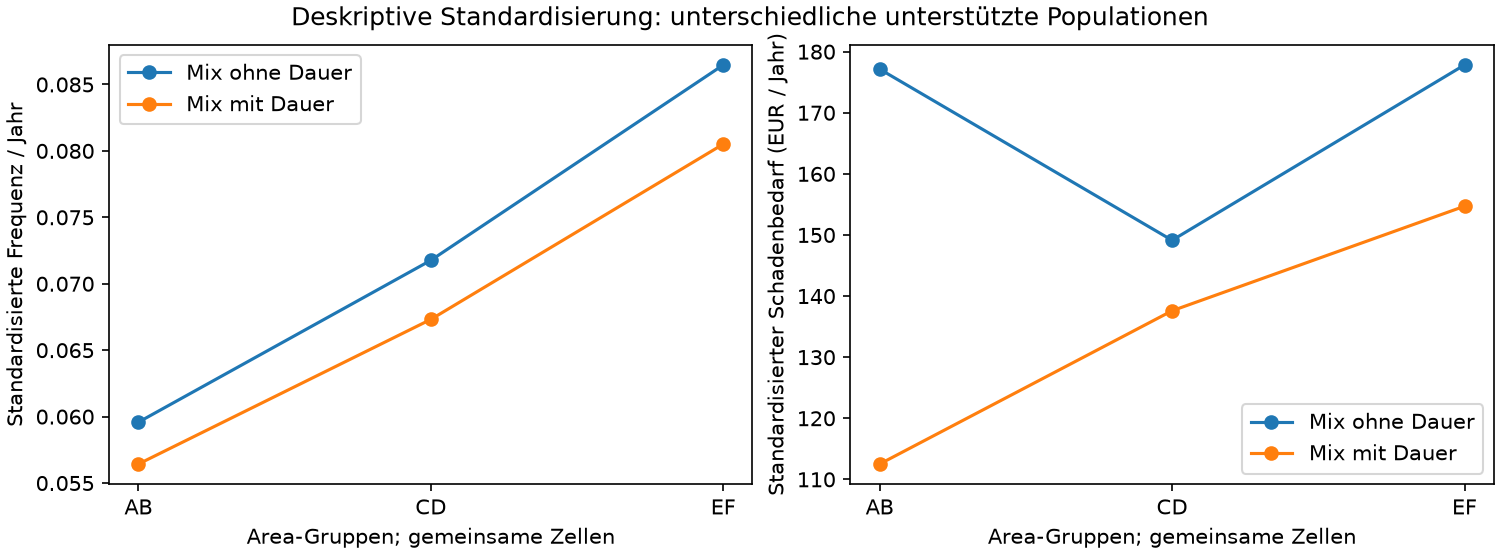

,model_id,assigned_age,standardized_annual_rate
0,gam_b20_l10,35,0.052486
1,gam_b20_l10,45,0.077730
2,gam_b20_l10,55,0.074113
3,glm_age_bm_a0001,35,0.064506
4,glm_age_bm_a0001,45,0.081771
5,glm_age_bm_a0001,55,0.072271
6,hgb_l15,35,0.055875
7,hgb_l15,45,0.077067
8,hgb_l15,55,0.072331


In [5]:
for tag in ['without_duration', 'with_duration']:
    display(Markdown(f'**{tag}**'))
    display(table(f'common_geo_{tag}')[['geo', 'policies', 'exposure_years', 'claims', 'severity_median_eur',
                                      'severity_p99_eur', 'annual_loss_eur', 'loss_share_ge_100000']].round(4))
    display(table(f'standardized_{tag}').rename(columns={
        'recorded_positive_count': 'Schadenzeilen / Jahr', 'recorded_loss_eur': 'Schadenbedarf EUR / Jahr',
        'glm_age_bm_a0001': 'GLM-Frequenz / Jahr', 'gam_b20_l10': 'GAM-Frequenz / Jahr'}).round(6))
    display(table(f'standardized_intervals_{tag}').query("geo == 'EF-minus-AB'").round(6))
display(Image(filename=str(REPORTS / 'figures/mix_dauer.png')))
display(table('existing_age_profiles')[['model_id', 'assigned_age', 'standardized_annual_rate']].round(6))

Die vollständigen Entwicklungsrefits liefern adjustierte Assoziationen auf beobachteten Verträgen. Die zusätzlichen Altersprofile stammen unverändert aus S4 und halten einen gemeinsamen unterstützten Referenzbestand fest. Sie sind keine kausalen Alterseffekte oder OOF-Gütemaße. Bonus-Malus kann Erfahrung, Schadenhistorie oder Selektion abbilden; seine kausale Rolle ist nicht allein durch seine Verfügbarkeit bestimmt.

Amtliche ONISR-Zahlen betreffen Unfallorte und körperliche Verletzungen; Cerema untersucht eine Geschwindigkeitsregel auf bestimmten Straßen ab 2018. freMTPL2 enthält Wohnortmerkmale und historische Versicherungszahlungen aus ungefähr 2011–2013. Diese externe Evidenz macht Mechanismen plausibel, identifiziert ihre Ursache im Portfolio aber nicht. [Quellen, tatsächliche Befunde und konkurrierende Erklärungen](../docs/aktuarische_einordnung.md#welche-mechanismen-lassen-sich-unterscheiden) bilden die Grundlage für eine spätere ausführliche Aufarbeitung in Paper und Präsentation.

## Kosten und fachliche Kommunikation

Für jährlichen Schadenbedarf q ohne weitere Lasten oder Steuern: `P_fix=q+50`, `P_var=q/0.85`. Schnittpunkt: `q=850/3≈283.33 EUR/Jahr`. Die variable Regel ist darunter günstiger, die Pauschale darüber. Es sind angenommene Kostenregeln, keine geschätzten Kanal- oder Profitabilitätseffekte.

In [6]:
costs = table('costs').query('supported').sort_values('q_eur_per_year')
examples = pd.concat([costs.head(3), costs.tail(3)]).drop_duplicates().copy()
examples['age'] = examples.age.astype(int).map({0: '18–24', 1: '25–34', 2: '35–49', 3: '50–64', 4: 'ab 65'})
if 'bm' in examples:
    examples['bm'] = examples.bm.astype(int).map({0: '50', 1: '51–75', 2: '76–100', 3: 'ab 101'})
display(examples.rename(columns={'age': 'Fahreralter', 'bm': 'Bonus-Malus',
    'q_eur_per_year': 'q EUR/Jahr', 'P_fix': 'P_fix EUR/Jahr', 'P_var': 'P_var EUR/Jahr'}).round(2))
assert ((costs.P_var-costs.q_eur_per_year)-.15*costs.P_var).abs().max() < 1e-9
calibration = table('geography_calibration')
display(calibration.query('model_id == @best and dimension in ["geo", "duration"]')[[
    'dimension', 'level', 'exposure_years', 'observed_annual_loss_eur', 'predicted_annual_loss_eur',
    'loss_actual_over_predicted']].round(4))

,Fahreralter,Bonus-Malus,policies,exposure_years,predicted_loss,q EUR/Jahr,P_fix EUR/Jahr,P_var EUR/Jahr,supported
4,25–34,50,14590,8746.32,760746.22,86.98,136.98,102.33,True
16,ab 65,50,49729,33387.00,3914886.75,117.26,167.26,137.95,True
8,35–49,50,126390,70521.11,9007314.07,127.73,177.73,150.26,True
7,25–34,ab 101,2313,1013.33,549242.12,542.01,592.01,637.66,True
3,18–24,ab 101,1903,846.14,625711.39,739.49,789.49,869.99,True
11,35–49,ab 101,1207,577.94,439298.59,760.11,810.11,894.25,True


,dimension,level,exposure_years,observed_annual_loss_eur,predicted_annual_loss_eur,loss_actual_over_predicted
51,geo,AB,83974.0226,164.7482,154.2177,1.0683
52,geo,CD,145362.1719,154.5156,165.1350,0.9357
53,geo,EF,57544.6244,194.3790,182.7996,1.0633
65,duration,0,19960.6888,594.1840,187.6990,3.1656
66,duration,1,88037.0200,200.4682,182.7093,1.0972
67,duration,2,178883.1100,100.4668,154.5256,0.6502


Ein gutes Portfolio-A/P garantiert keinen passenden Schadenbedarf jeder Risikogruppe. Kanalpreise erfordern zurechenbare Kosten und vergleichbare Deckung; für Deutschland braucht es aktuelle Zielmarktdaten und externe Validierung. Niedrigere Preise belegen weder Kostendeckung noch Profitabilität. Die [kurzen Fachgesprächsantworten](../docs/aktuarische_einordnung.md#kurze-antworten-im-fachgespräch) verbinden diese Entscheidungen mit ihren Belegen und Grenzen.